# ClimaCity Paris -- 06. Optimisation et bilan d'architecture (Jour 3 après-midi)

Ce dernier carnet regarde **comment** Spark exécute les traitements des jours précédents, et ce qu'ils
coûtent :

1. le **stage le plus lent** du Jour 2, lu dans le Spark UI (API REST), et ses causes ;
2. un **déséquilibre de données** (*data skew*) et sa correction par repartitionnement ;
3. la jointure météo : **broadcast** contre **SortMergeJoin** ;
4. le **nombre de partitions** des calculs itératifs du clustering ;
5. Pandas contre Spark selon le volume ;
6. le **bilan d'architecture** : quand Spark vaut-il le coût de son overhead ? Il s'appuie sur les
   mesures rangées dans `data/output/mesures.json` par tous les carnets.

Chaque mesure modifie un réglage de la session (exécution adaptative, seuil de broadcast) **le temps de
la mesure seulement**, puis le rétablit. Les durées varient d'une exécution à l'autre ; on répète les
mesures courtes et on garde la médiane.

## 1. Session et outils de mesure

`stages_spark_ui` (dans `config.py`) lit les stages d'un job dans l'API REST du Spark UI. On y ajoute la
**distribution des durées de tâches** de chaque stage (`taskSummary` : minimum, médiane, maximum) : c'est
elle qui révèle un déséquilibre, invisible dans la durée totale.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..", "scripts").resolve()))
from config import *          # chemins, SEED, SHUFFLE_PARTITIONS, creer_session()

import json
import statistics
import time

import matplotlib.pyplot as plt
import pandas as pd
import requests
from pyspark import StorageLevel
from pyspark.ml.clustering import KMeans
from pyspark.ml.feature import VectorAssembler
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = creer_session("ClimaCity-06-optimisation-bilan",
                      spark__ui__retainedJobs="10000", spark__ui__retainedStages="10000")
sc = spark.sparkContext
API = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"
print("Spark", spark.version, "| cœurs :", sc.defaultParallelism, "| Spark UI :", sc.uiWebUrl)


def distribution_taches(description: str) -> pd.DataFrame:
    """Résume les stages d'une action, avec la distribution de la durée de leurs tâches.

    Args:
        description: Texte passé à ``sc.setJobDescription`` avant l'action.

    Returns:
        Un DataFrame Pandas (une ligne par stage exécuté de plus d'une tâche) : tâches, temps de
        calcul cumulé, volume lu et shuffle écrit, durée minimale, médiane et maximale d'une
        tâche, rapport max / médiane, et lignes de shuffle lues par la tâche la plus chargée.

    Example:
        >>> sc.setJobDescription("test"); df.count()                  # doctest: +SKIP
        >>> distribution_taches("test")["max_sur_mediane"].max()     # doctest: +SKIP
        1.1
    """
    lignes = []
    for s in stages_spark_ui(spark, description, tous_les_jobs=True):
        if s["statut"] != "COMPLETE" or s["taches"] < 2:
            continue
        q = requests.get(f"{API}/stages/{s['stage']}/0/taskSummary?quantiles=0,0.5,1.0", timeout=10).json()
        duree = [x / 1000 for x in q["executorRunTime"]]
        lignes.append({
            "stage": s["stage"], "nom": s["nom"][:30], "taches": s["taches"], "calcul_s": round(s["calcul_s"], 1),
            "entree_mo": round(s["entree_mo"], 1), "shuffle_ecrit_mo": round(s["shuffle_ecrit_ko"] / 1e3, 1),
            "tache_min_s": round(duree[0], 2), "tache_mediane_s": round(duree[1], 2), "tache_max_s": round(duree[2], 2),
            "max_sur_mediane": round(duree[2] / duree[1], 1) if duree[1] else None,
            "lignes_shuffle_max": int(q["shuffleReadMetrics"]["readRecords"][2]),
        })
    return pd.DataFrame(lignes).set_index("stage")


def chronometrer(action, repetitions: int = 3) -> float:
    """Exécute plusieurs fois une action Spark et renvoie la durée médiane.

    Args:
        action: Fonction sans argument qui déclenche un calcul Spark.
        repetitions: Nombre d'exécutions.

    Returns:
        La médiane des durées, en secondes.

    Example:
        >>> chronometrer(lambda: spark.range(10).count())   # doctest: +SKIP
        0.08
    """
    durees = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        action()
        durees.append(time.perf_counter() - t0)
    return statistics.median(durees)


mesures = {}

Spark 3.5.3 | cœurs : 8 | Spark UI : http://b7268ef2058c:4040


## 2. Le stage le plus lent du Jour 2

On rejoue le calcul le plus lourd du carnet 03 : la vue `releves` (table consolidée, calendrier de Paris,
jointures météo et jours fériés) puis les **fonctions de fenêtre** (`LAG`, `LEAD`, moyenne mobile sur
3 heures). L'écriture vers le format `noop` exécute tout le plan sans rien écrire : on mesure le calcul
seul.

In [2]:
COLONNES_CIBLE = ["station_id", "nom_station", "arrondissement", "latitude", "longitude", "horodatage",
                  "velos_mecaniques", "velos_electriques", "bornettes_libres", "capacite_totale",
                  "taux_occupation"]
spark.read.parquet(str(PARQUET_CONSOLIDE)).select(*COLONNES_CIBLE).createOrReplaceTempView("disponibilite")
spark.read.parquet(str(METEO_PARQUET)).createOrReplaceTempView("meteo_horaire")

REQUETE_RELEVES = """
SELECT d.station_id, d.arrondissement, d.horodatage, d.taux_occupation,
       d.velos_mecaniques + d.velos_electriques AS velos,
       hour(from_utc_timestamp(d.horodatage, 'Europe/Paris')) AS heure,
       m.temperature_c, m.est_pluie
FROM disponibilite d
LEFT JOIN meteo_horaire m ON m.horodatage = date_trunc('HOUR', d.horodatage + INTERVAL 30 MINUTES)
"""
spark.sql(REQUETE_RELEVES).createOrReplaceTempView("releves")
fenetres = spark.sql("""
SELECT station_id, horodatage,
       LAG(taux_occupation)  OVER w AS taux_precedent,
       LEAD(taux_occupation) OVER w AS taux_suivant,
       velos - LAG(velos) OVER w    AS delta_velos,
       AVG(taux_occupation) OVER w3h AS moyenne_mobile_3h
FROM releves
WINDOW w   AS (PARTITION BY station_id ORDER BY horodatage),
       w3h AS (PARTITION BY station_id ORDER BY horodatage RANGE BETWEEN INTERVAL 3 HOURS PRECEDING AND CURRENT ROW)
""")

sc.setJobDescription("jour 2 : fonctions de fenêtre")
t0 = time.perf_counter()
fenetres.write.format("noop").mode("overwrite").save()
duree_fenetres = time.perf_counter() - t0
sc.setJobDescription(None)
stages_jour2 = distribution_taches("jour 2 : fonctions de fenêtre")
print(f"Calcul complet en {duree_fenetres:.1f} s")
stages_jour2

Calcul complet en 3.7 s


,nom,taches,calcul_s,entree_mo,shuffle_ecrit_mo,tache_min_s,tache_mediane_s,tache_max_s,max_sur_mediane,lignes_shuffle_max
stage,,,,,,,,,,
3,save at NativeMethodAccessorIm,9,5.2,48.6,115.9,0.04,0.67,1.09,1.6,0
5,save at NativeMethodAccessorIm,8,14.8,0.0,0.0,1.68,1.89,1.93,1.0,1466910


Le plan physique montre où se trouvent les échanges (`Exchange`, c'est-à-dire les shuffles) et la
stratégie de jointure :

In [3]:
plan = fenetres._jdf.queryExecution().executedPlan().toString()
for ligne in plan.splitlines():
    if any(mot in ligne for mot in ["Exchange", "Join", "Window", "Sort ", "Scan parquet"]):
        print(ligne.strip()[:150])

+- Window [lag(taux_occupation#11, -1, null) windowspecdefinition(station_id#1, horodatage#6 ASC NULLS FIRST, specifiedwindowframe(RowFrame, -1, -1)) 
+- Sort [station_id#1 ASC NULLS FIRST, horodatage#6 ASC NULLS FIRST], false, 0
+- Exchange hashpartitioning(station_id#1, 8), ENSURE_REQUIREMENTS, [plan_id=201]
+- BroadcastHashJoin [date_trunc(HOUR, horodatage#6 + INTERVAL '30' MINUTE, Some(UTC))], [horodatage#62], LeftOuter, BuildRight, false
:  +- FileScan parquet [station_id#1,horodatage#6,velos_mecaniques#7,velos_electriques#8,taux_occupation#11,annee#23,mois#24] Batched: true, DataFilte
+- BroadcastExchange HashedRelationBroadcastMode(List(input[0, timestamp, false]),false), [plan_id=197]
+- FileScan parquet [horodatage#62] Batched: true, DataFilters: [isnotnull(horodatage#62)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file


Le calcul tient en **deux stages**, séparés par l'unique shuffle du plan (`Exchange hashpartitioning(station_id, 8)`) :

- **le stage de lecture** (9 tâches) lit 49 Mo de Parquet (les seules colonnes utiles), fait la jointure météo en **broadcast** (`BroadcastHashJoin`) et écrit environ **116 Mo de shuffle** : les 10,8 millions de lignes redistribuées par station ;
- **le stage des fenêtres** (8 tâches) est **le plus lent** : de 15 à 17 s de calcul cumulé selon l'exécution, contre 5 s pour la lecture. Chaque tâche reçoit les relevés d'environ 170 stations (jusqu'à 1,5 million de lignes), les **trie** par station et horodatage, puis calcule `LAG`, `LEAD` et la moyenne mobile.

Le diagnostic, cause par cause :

- **déséquilibre (skew)** : non. Les tâches durent toutes environ 2 s, rapport max / médiane de 1,0. Les 1 382 stations ont presque toutes le même nombre de relevés, et le hachage les répartit bien en 8 partitions. La lecture est un peu moins régulière (rapport de 1,7) : les fichiers Parquet mensuels n'ont pas la même taille (décembre est le plus gros) ;
- **broadcast manqué** : non, la petite table météo est diffusée ;
- **partitionnement** : c'est la vraie cause. Les données ne sont pas rangées par station sur disque, donc chaque calcul de fenêtre doit tout redistribuer puis trier. Les remèdes sont de **mettre le résultat en cache** quand il sert plusieurs fois (ce que fait le carnet 03, avec `CACHE TABLE features_temporelles`), ou d'écrire la table **pré-partitionnée par station** (`bucketBy`), pour que les lectures suivantes évitent le shuffle.

Avec 8 tâches pour 8 cœurs, le stage est déjà parallélisé au maximum de la machine : en mode local, plus de partitions n'irait pas plus vite.

## 3. Un déséquilibre de données, corrigé par repartitionnement

Pour provoquer un vrai déséquilibre, on change la clé de partition de la fenêtre : la **moyenne mobile
sur 3 heures du taux d'occupation de tout l'arrondissement**, à chaque relevé. La fenêtre est partitionnée
par `arrondissement` : il n'y a plus que 42 clés, de tailles très inégales (de quelques milliers de relevés
pour une petite commune à 700 000 pour le 15e). Avec 8 partitions de shuffle, plusieurs gros arrondissements
tombent dans la même partition.

L'exécution adaptative (AQE) est **désactivée** pendant la mesure : elle pourrait regrouper les partitions
après coup et brouiller la comparaison. Son traitement automatique du déséquilibre (`skewJoin`) ne concerne
de toute façon que les jointures, pas les fenêtres.

In [4]:
releves_arr = spark.read.parquet(str(PARQUET_CONSOLIDE)).select("arrondissement", "horodatage", "taux_occupation")
releves_arr.groupBy("arrondissement").count().agg(
    F.count("*").alias("cles"), F.min("count").alias("min"), F.expr("percentile(count, 0.5)").alias("mediane"),
    F.max("count").alias("max")).show()

fenetre_arr = (Window.partitionBy("arrondissement").orderBy(F.col("horodatage").cast("long"))
               .rangeBetween(-3 * 3600, 0))
spark.conf.set("spark.sql.adaptive.enabled", "false")
resultats_skew = {}
for n_partitions in [8, 64]:
    description = f"skew : {n_partitions} partitions"
    donnees = releves_arr.repartition(n_partitions, "arrondissement")
    sc.setJobDescription(description)
    duree = chronometrer(lambda: donnees.withColumn("moyenne_arr_3h", F.avg("taux_occupation").over(fenetre_arr))
                         .write.format("noop").mode("overwrite").save())
    sc.setJobDescription(None)
    taches = distribution_taches(description)
    stage_fenetre = taches[taches["taches"] == n_partitions].iloc[-1]
    par_partition = sorted((r["count"] for r in donnees.groupBy(F.spark_partition_id()).count().collect()),
                           reverse=True)
    resultats_skew[n_partitions] = {"duree_s": round(duree, 2), "tache_max_s": stage_fenetre["tache_max_s"],
                                    "tache_mediane_s": stage_fenetre["tache_mediane_s"],
                                    "lignes_partition_max": par_partition[0],
                                    "lignes_partition_min": par_partition[-1] if len(par_partition) == n_partitions else 0,
                                    "partitions_vides": n_partitions - len(par_partition)}
spark.conf.set("spark.sql.adaptive.enabled", "true")
mesures["skew_fenetre_arrondissement"] = resultats_skew
pd.DataFrame(resultats_skew).T

+----+----+--------+------+
|cles| min| mediane|   max|
+----+----+--------+------+
|  43|3093|204516.0|702746|
+----+----+--------+------+



,duree_s,tache_max_s,tache_mediane_s,lignes_partition_max,lignes_partition_min,partitions_vides
8,1.70,1.13,0.75,2194802.0,47196.0,0.0
64,1.58,0.67,0.01,1185152.0,0.0,36.0


Le déséquilibre est net avec **8 partitions** : la partition la plus chargée reçoit **2,2 millions de lignes** (plusieurs gros arrondissements hachés au même endroit), la moins chargée 47 000. La tâche la plus longue dure de 1,1 à 1,6 s selon l'exécution, et le stage attend toujours sa tâche la plus lente.

Avec **64 partitions**, chaque partition ne reçoit plus qu'un ou deux arrondissements : la plus grosse tombe à **1,2 million de lignes** et la plus longue tâche à 0,7 s, soit environ deux fois moins. La durée totale baisse moins (de 7 à 25 % selon les exécutions), car la lecture et l'écriture du shuffle, inchangées, en forment une bonne part. Le repartitionnement a ses limites :

- **36 partitions sur 64 sont vides** : avec 43 clés, le hachage en laisse forcément beaucoup sans données. Elles coûtent peu ici, mais chacune reste une tâche à planifier ;
- on ne peut pas descendre sous la taille de **la plus grosse clé** (le 15e, 700 000 relevés), que le hachage ne coupe jamais. Pour aller plus loin, il faudrait **saler** la clé (la découper en sous-clés, puis recombiner), ou **pré-agréger** par arrondissement et par horodatage : 43 × 7 900 lignes au lieu de 10,8 millions. C'est d'ailleurs la vraie bonne solution pour cette moyenne.

## 4. Jointure météo : broadcast contre SortMergeJoin

La vue `releves` joint 10,8 millions de relevés à la table `meteo_horaire` (3 240 lignes, quelques
dizaines de ko). Deux stratégies :

- **broadcast** : la petite table est envoyée en entier à chaque tâche ; la grande table n'a pas à bouger ;
- **SortMergeJoin** : les deux tables sont redistribuées (shuffle) par clé de jointure, triées, puis
  fusionnées.

Spark choisit le broadcast tout seul quand une table fait moins de `spark.sql.autoBroadcastJoinThreshold`
(10 Mo par défaut). Pour mesurer la SortMergeJoin, on met ce seuil à `-1` **le temps de la mesure** :
cela désactive aussi la conversion en broadcast par l'AQE, qui utilise le même seuil par défaut. La requête
n'a pas d'indice `BROADCAST`, qui l'emporterait sur le seuil.

In [5]:
def strategie_jointure(df) -> str:
    """Renvoie la stratégie de jointure retenue dans le plan physique d'un DataFrame.

    Args:
        df: DataFrame qui contient une jointure.

    Returns:
        ``"BroadcastHashJoin"``, ``"SortMergeJoin"`` ou ``"ShuffledHashJoin"``.

    Example:
        >>> strategie_jointure(spark.sql(REQUETE_RELEVES))   # doctest: +SKIP
        'BroadcastHashJoin'
    """
    plan = df._jdf.queryExecution().executedPlan().toString()
    return next(s for s in ["BroadcastHashJoin", "SortMergeJoin", "ShuffledHashJoin"] if s in plan)


resultats_jointure = {}
for nom, seuil in [("broadcast", "10MB"), ("sort_merge", "-1")]:
    spark.conf.set("spark.sql.autoBroadcastJoinThreshold", seuil)
    jointure = spark.sql(REQUETE_RELEVES)
    description = f"jointure météo : {nom}"
    sc.setJobDescription(description)
    duree = chronometrer(lambda: jointure.write.format("noop").mode("overwrite").save())
    sc.setJobDescription(None)
    taches = distribution_taches(description)
    resultats_jointure[nom] = {"strategie": strategie_jointure(jointure), "duree_s": round(duree, 2),
                               "stages_par_execution": len(taches) // 3,
                               "shuffle_ecrit_mo": round(taches["shuffle_ecrit_mo"].sum() / 3, 1),
                               "calcul_cumule_s": round(taches["calcul_s"].sum() / 3, 1)}
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "10MB")
mesures["jointure_meteo"] = resultats_jointure
pd.DataFrame(resultats_jointure).T

,strategie,duree_s,stages_par_execution,shuffle_ecrit_mo,calcul_cumule_s
broadcast,BroadcastHashJoin,0.94,1,0.0,3.7
sort_merge,SortMergeJoin,1.87,2,181.3,10.7


Le **broadcast** est deux fois plus rapide (environ 1 s contre 2 s) et n'écrit **aucun shuffle**. La SortMergeJoin redistribue les 10,8 millions de relevés par heure de jointure (**181 Mo de shuffle**), les trie, puis les fusionne avec la météo : un stage de plus, et presque trois fois plus de temps de calcul cumulé.

Le gain est modeste en valeur absolue parce que tout tient sur une machine (le shuffle reste sur le disque local), mais il serait bien plus grand sur un cluster, où le shuffle passe par le réseau. Le broadcast n'a de sens que si la petite table tient dans la mémoire de chaque exécuteur : c'est le cas de la météo (3 240 lignes), pas d'une table de relevés. Spark le choisit seul ici, sous le seuil de 10 Mo : le réglage qui compte est surtout de **ne pas l'empêcher**, par exemple en joignant sur une expression que Spark ne sait pas estimer.

## 5. Nombre de partitions des calculs itératifs du clustering

Le K-Means du carnet 05 travaille sur **1 381 vecteurs de 24 valeurs** : environ 300 ko. Deux réglages
de partitions interviennent :

1. `spark.sql.shuffle.partitions` pour **construire les profils** (agrégation des 10,7 millions de relevés) ;
2. le nombre de partitions des **profils eux-mêmes**, sur lesquels K-Means itère : chaque itération lance
   une tâche par partition.

L'AQE est désactivée pendant la mesure : sinon, elle regrouperait d'elle-même les petites partitions de
shuffle, ce qui est justement l'effet qu'on veut observer à la main.

In [6]:
HEURES = list(range(24))
releves_ouvres = (spark.read.format("delta").load(str(DELTA_DISPONIBILITE))
                  .withColumn("paris", F.from_utc_timestamp("horodatage", "Europe/Paris"))
                  .filter(F.dayofweek("paris").between(2, 6)))


def construire_profils():
    """Calcule le profil horaire moyen (jours ouvrés) de chaque station, comme au carnet 05.

    Returns:
        Un DataFrame ``station_id``, ``features`` (24 valeurs), trié par station.

    Example:
        >>> construire_profils().count()   # doctest: +SKIP
        1381
    """
    pivot = (releves_ouvres.groupBy("station_id", F.hour("paris").alias("h"))
             .agg(F.avg("taux_occupation").alias("taux"))
             .groupBy("station_id").pivot("h", HEURES).agg(F.first("taux")))
    return (VectorAssembler(inputCols=[str(h) for h in HEURES], outputCol="features", handleInvalid="skip")
            .transform(pivot).select("station_id", "features").orderBy("station_id"))


spark.conf.set("spark.sql.adaptive.enabled", "false")
resultats_profils = {}
for n_shuffle in [8, 200]:
    spark.conf.set("spark.sql.shuffle.partitions", n_shuffle)
    description = f"profils : {n_shuffle} partitions de shuffle"
    sc.setJobDescription(description)
    duree = chronometrer(lambda: construire_profils().write.format("noop").mode("overwrite").save())
    sc.setJobDescription(None)
    taches = distribution_taches(description)
    resultats_profils[n_shuffle] = {"duree_s": round(duree, 2), "taches_par_execution": int(taches["taches"].sum() / 3),
                                    "tache_mediane_s": float(taches["tache_mediane_s"].median())}
spark.conf.set("spark.sql.shuffle.partitions", SHUFFLE_PARTITIONS)
mesures["profils_shuffle_partitions"] = resultats_profils
pd.DataFrame(resultats_profils).T

,duree_s,taches_par_execution,tache_mediane_s
8,1.22,90.0,0.01
200,2.26,858.0,0.01


Puis les itérations elles-mêmes : la même boucle K-Means (k de 3 à 8) sur les profils persistés en
**1, 8, 64 et 200 partitions**. On vérifie que l'inertie ne dépend pas du découpage (à l'arrondi près).

In [7]:
profils = construire_profils().coalesce(1).persist(StorageLevel.MEMORY_ONLY)
profils.count()
resultats_kmeans = {}
for n_partitions in [1, 8, 64, 200]:
    donnees = (profils if n_partitions == 1 else profils.repartition(n_partitions)).persist(StorageLevel.MEMORY_ONLY)
    donnees.count()
    description = f"kmeans : {n_partitions} partitions"
    sc.setJobDescription(description)
    t0 = time.perf_counter()
    inerties = [KMeans(k=k, seed=SEED, maxIter=50).fit(donnees).summary.trainingCost for k in range(3, 9)]
    duree = time.perf_counter() - t0
    sc.setJobDescription(None)
    taches = stages_spark_ui(spark, description, tous_les_jobs=True)
    resultats_kmeans[n_partitions] = {"duree_s": round(duree, 2), "jobs": len({t["job"] for t in taches}),
                                      "taches": sum(t["taches"] for t in taches if t["statut"] == "COMPLETE"),
                                      "inertie_k4": round(inerties[1], 3)}
    if donnees is not profils:
        donnees.unpersist()
spark.conf.set("spark.sql.adaptive.enabled", "true")
mesures["kmeans_partitions"] = resultats_kmeans
tableau_kmeans = pd.DataFrame(resultats_kmeans).T
tableau_kmeans.index.name = "partitions"
tableau_kmeans

,duree_s,jobs,taches,inertie_k4
partitions,,,,
1,2.50,149.0,250.0,299.613
8,3.01,184.0,2614.0,299.757
64,7.50,178.0,19766.0,299.613
200,11.79,128.0,41654.0,299.629


Pour des données aussi petites, **moins il y a de partitions, mieux c'est** :

- **construction des profils** : 200 partitions de shuffle (la valeur par défaut de Spark) au lieu de 8 donnent près de 10 fois plus de tâches (858 contre 90) qui ne font presque rien (10 ms en médiane), et une durée presque doublée. C'est pourquoi le projet fixe `spark.sql.shuffle.partitions = 8` dans `config.py`, et pourquoi l'AQE, qui regroupe automatiquement ces petites partitions, est activée par défaut ;
- **itérations de K-Means** : chaque itération lance une tâche par partition. Avec 200 partitions, la boucle k = 3..8 exécute plus de **41 000 tâches** et dure **environ 12 s**, contre 250 tâches et **2,5 s** avec une seule partition. Le coût de planification d'une tâche (quelques millisecondes) dépasse de loin le calcul utile sur 7 vecteurs.

La bonne taille d'une partition se compte en dizaines ou centaines de Mo, pas en lignes : les 300 ko de profils tiennent dans une seule. Les petites différences d'inertie selon le découpage viennent de l'initialisation de K-Means, qui tire ses points partition par partition (voir le carnet 05).

## 6. Pandas contre Spark, selon le volume

Le carnet 01 comparait Pandas et Spark sur un seul fichier CSV. On reprend la comparaison sur la table
Parquet consolidée, pour un même calcul (taux d'occupation moyen par station et par heure de la journée)
et des volumes croissants : 1, 2, 4 puis 6 mois. Côté Pandas, on ne lit que les trois colonnes utiles, et
on mesure la mémoire occupée par le DataFrame.

C'est le seul endroit du projet où Pandas traite plus de 10 000 lignes : c'est l'objet même de la mesure.

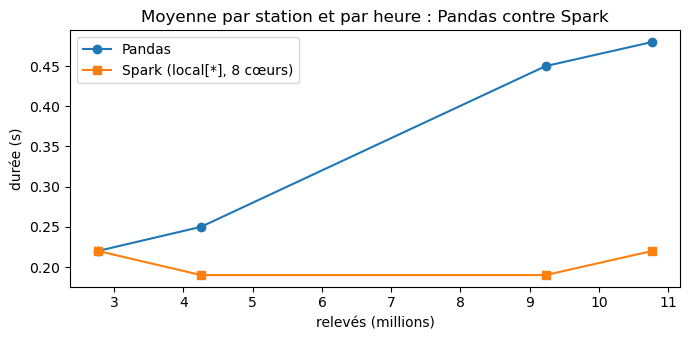

,lignes,pandas_s,pandas_memoire_mo,spark_s
mois,,,,
1,2766662,0.22,66,0.22
2,4253148,0.25,102,0.19
4,9229381,0.45,222,0.19
6,10769262,0.48,258,0.22


In [8]:
MOIS = [(2020, 12), (2021, 1), (2021, 2), (2021, 3), (2020, 11), (2021, 4)]     # du plus gros au plus petit
resultats_volume = []
for n_mois in [1, 2, 4, 6]:
    choisis = MOIS[:n_mois]
    filtre = [[("annee", "=", a), ("mois", "=", m)] for a, m in choisis]

    t0 = time.perf_counter()
    pdf = pd.read_parquet(PARQUET_CONSOLIDE, columns=["station_id", "horodatage", "taux_occupation"], filters=filtre)
    pdf["heure"] = pdf["horodatage"].dt.hour
    resultat_pandas = pdf.groupby(["station_id", "heure"])["taux_occupation"].mean()
    duree_pandas = time.perf_counter() - t0
    memoire_mo = pdf.memory_usage(deep=True).sum() / 1e6
    lignes = len(pdf)
    del pdf

    condition = " OR ".join(f"(annee = {a} AND mois = {m})" for a, m in choisis)
    sdf = (spark.read.parquet(str(PARQUET_CONSOLIDE)).filter(condition)
           .groupBy("station_id", F.hour("horodatage").alias("heure")).agg(F.avg("taux_occupation")))
    duree_spark = chronometrer(lambda: sdf.collect(), repetitions=2)
    assert sdf.count() == len(resultat_pandas)
    resultats_volume.append({"mois": n_mois, "lignes": lignes, "pandas_s": round(duree_pandas, 2),
                             "pandas_memoire_mo": round(memoire_mo), "spark_s": round(duree_spark, 2)})
mesures["pandas_contre_spark"] = resultats_volume
volume = pd.DataFrame(resultats_volume).set_index("mois")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(volume["lignes"] / 1e6, volume["pandas_s"], marker="o", label="Pandas")
ax.plot(volume["lignes"] / 1e6, volume["spark_s"], marker="s", label="Spark (local[*], 8 cœurs)")
ax.set_xlabel("relevés (millions)")
ax.set_ylabel("durée (s)")
ax.set_title("Moyenne par station et par heure : Pandas contre Spark")
ax.legend()
plt.tight_layout()
plt.show()
volume

Sur Parquet, **Spark fait jeu égal avec Pandas sur un mois de données** (environ 0,2 s chacun), puis le dépasse : à 6 mois, 0,2 s contre 0,5 s. La durée de Spark ne bouge presque pas avec le volume, celle de Pandas croît avec le nombre de lignes. C'est l'inverse du carnet 01, où Pandas battait Spark sur un fichier CSV compressé (2,0 s contre 2,3 à 8 s). La différence tient au format : un gzip ne se découpe pas (une seule tâche par fichier) et doit être parsé ligne à ligne, alors que Parquet se lit en colonnes, en parallèle sur 8 cœurs, avec élagage des partitions et des colonnes.

Pandas reste très raisonnable à ce volume : **258 Mo de mémoire** pour trois colonnes et 10,8 millions de lignes. Les durées sont celles d'une exécution à chaud (fichiers en cache du système, JVM déjà lancée).

## 7. Bilan d'architecture

On rassemble les mesures de tous les carnets (`mesures.json`) avec celles de ce carnet.

In [9]:
enregistrer_mesures("06_optimisation_bilan", {"fenetres_jour2_s": round(duree_fenetres, 2), **mesures})
toutes = json.loads(MESURES_JSON.read_text(encoding="utf-8"))
m01, m02, m03 = toutes["01_rdd_exploration"], toutes["02_dataframe_pipeline"], toutes["03_spark_sql_delta"]
m04, m05, m06 = toutes["04_streaming"], toutes["05_mllib_prediction"], toutes["06_optimisation_bilan"]

bilan = pd.DataFrame([
    ("01", "1 fichier CSV (1,6 M lignes) : Pandas / Spark 1 partition / Spark 8 partitions",
     f"{m01['pandas_1_fichier_s']} s / {m01['spark_rdd_1_fichier_1_partition_s']} s / {m01['spark_rdd_1_fichier_8_partitions_s']} s"),
    ("01", "RDD : 1er comptage (lecture gzip + parsing) / depuis le cache",
     f"{m01['count_1_lecture_parsing_cache_s']} s / {m01['count_2_depuis_cache_s']} s"),
    ("02", "Schéma : inferSchema / schéma explicite",
     f"{m02['definition_inferschema_s']} s / {m02['definition_schema_explicite_s']} s"),
    ("02", "Jointure (contrainte 6) : sans cache / météo en cache / disponibilite en cache",
     f"{m02['jointure_sans_cache_s']} s / {m02['jointure_meteo_cache_s']} s / {m02['jointure_meteo_et_disponibilite_cache_s']} s"),
    ("02", "Stockage : CSV gzip / Parquet (25 colonnes au lieu de 7)", f"{m02['csv_gzip_mo']} Mo / {m02['parquet_mo']} Mo"),
    ("03", "CACHE TABLE releves / requête Q1 sur le cache", f"{m03['cache_table_releves_s']} s / {m03['q1_s']} s"),
    ("03", "Delta : écriture / MERGE (84 692 insertions, 612 mises à jour)",
     f"{m03['ecriture_delta_disponibilite_s']} s / {m03['merge_s']} s"),
    ("04", "Streaming : durée moyenne d'un micro-lot de 1 367 relevés", f"{m04['duree_moyenne_lot_donnees_ms'] / 1000:.1f} s"),
    ("05", "GBT : validation croisée (18 entraînements) / champion (3,5 M lignes)",
     f"{m05['validation_croisee_s']} s / {m05['entrainement_champion_s']} s"),
    ("05", "K-Means k = 3..8 (contrainte 6) : sans cache / avec cache",
     f"{m05['kmeans_sans_cache_s']} s / {m05['kmeans_avec_cache_s']} s"),
    ("06", "Fenêtre par arrondissement : 8 / 64 partitions",
     f"{m06['skew_fenetre_arrondissement']['8']['duree_s']} s / {m06['skew_fenetre_arrondissement']['64']['duree_s']} s"),
    ("06", "Jointure météo : broadcast / SortMergeJoin",
     f"{m06['jointure_meteo']['broadcast']['duree_s']} s / {m06['jointure_meteo']['sort_merge']['duree_s']} s"),
    ("06", "K-Means k = 3..8 : 1 / 200 partitions",
     f"{m06['kmeans_partitions']['1']['duree_s']} s / {m06['kmeans_partitions']['200']['duree_s']} s"),
    ("06", "6 mois (10,8 M lignes), moyenne par station et heure : Pandas / Spark",
     f"{m06['pandas_contre_spark'][-1]['pandas_s']} s / {m06['pandas_contre_spark'][-1]['spark_s']} s"),
], columns=["carnet", "mesure", "résultat"])
pd.set_option("display.max_colwidth", 120)
bilan.style.hide(axis="index")

carnet,mesure,résultat
01,"1 fichier CSV (1,6 M lignes) : Pandas / Spark 1 partition / Spark 8 partitions",2.02 s / 7.99 s / 2.29 s
01,RDD : 1er comptage (lecture gzip + parsing) / depuis le cache,14.07 s / 0.55 s
02,Schéma : inferSchema / schéma explicite,3.66 s / 0.159 s
02,Jointure (contrainte 6) : sans cache / météo en cache / disponibilite en cache,8.76 s / 8.08 s / 0.65 s
02,Stockage : CSV gzip / Parquet (25 colonnes au lieu de 7),231.9 Mo / 149.2 Mo
03,CACHE TABLE releves / requête Q1 sur le cache,5.51 s / 1.63 s
03,"Delta : écriture / MERGE (84 692 insertions, 612 mises à jour)",4.98 s / 7.2 s
04,Streaming : durée moyenne d'un micro-lot de 1 367 relevés,2.3 s
05,"GBT : validation croisée (18 entraînements) / champion (3,5 M lignes)",153.4 s / 53.1 s
05,K-Means k = 3..8 (contrainte 6) : sans cache / avec cache,41.3 s / 2.5 s


### Quand Spark vaut-il le coût de son overhead ?

Les mesures des trois jours dessinent une réponse nuancée.

**1. Spark a un coût fixe, que les petits volumes ne compensent pas.** Chaque action lance un job, découpé en stages et en tâches, avec une planification de quelques millisecondes par tâche. Sur un fichier CSV de 1,6 million de lignes, Pandas est plus rapide (carnet 01). Avec trop de partitions, K-Means passe 5 fois plus de temps à planifier qu'à calculer (section 5). Un micro-lot de streaming de 1 367 relevés prend environ 2,3 s (carnet 04) : Structured Streaming vise une latence de l'ordre de la seconde, pas de la milliseconde.

**2. Le format et le parallélisme comptent plus que l'outil.** Sur Parquet, Spark fait jeu égal avec Pandas dès un mois de relevés et le dépasse au-delà (section 6). Le passage de CSV gzip à Parquet a réduit le stockage de 232 à 149 Mo avec 18 colonnes de plus, et rendu le comptage d'un mois quasi instantané (carnet 02). Le schéma explicite évite une passe complète sur les données (`inferSchema`, carnet 02).

**3. Le shuffle est le vrai coût, et il se pilote.** Tous les stages lents du projet suivent un shuffle : fonctions de fenêtre (section 2), dédoublonnage (carnet 02), SortMergeJoin (section 4). Les leviers mesurés : **broadcast** des petites tables (2 fois plus rapide, zéro shuffle), **nombre de partitions** adapté au volume (8 et non 200), **repartitionnement** d'une clé déséquilibrée (section 3).

**4. Le cache ne paie que si la donnée resert.** Persister la météo seule n'a rien changé, persister `disponibilite` a divisé la jointure par 13 (carnet 02). Pour un calcul itératif, le cache est indispensable : 16 fois plus rapide sur la boucle K-Means, et des résultats reproductibles (carnet 05).

**5. Ce qui justifie Spark ici, c'est la chaîne, pas un calcul isolé.** À 11 millions de lignes (230 Mo compressés), une machine et Pandas suffiraient pour la plupart des agrégations. Spark apporte ce que Pandas n'offre pas : une même API du RDD au SQL, des écritures **transactionnelles** et du time travel (Delta), un **flux** avec watermark et reprise sur checkpoint, des **pipelines** de ML sérialisables et une validation croisée parallèle. Il apporte surtout un passage à l'échelle **sans réécriture** : avec l'historique complet depuis 2019, toutes les villes, ou un flux à la minute, la même chaîne tournerait sur un cluster. Le carnet 01 montrait déjà que Pandas aurait besoin d'environ 3 Go de mémoire pour les seuls fichiers bruts de cet hiver.

**En résumé** : Spark vaut son overhead quand les données ne tiennent plus en mémoire d'une machine, quand le traitement doit être continu (streaming), ou quand la chaîne doit grandir sans être réécrite. En dessous, son intérêt dépend des réglages : format colonne, partitions dimensionnées au volume, broadcast, cache des données réutilisées.

In [10]:
profils.unpersist()
spark.stop()
print("SparkSession arrêtée.")

SparkSession arrêtée.
